# Component 2 — Phone-Only Model 


In [1]:
import sys, os, json
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = os.path.join(REPO_ROOT, "results", "component2_phonation")
METRICS_PATH = os.path.join(RESULTS_DIR, "phone_only_metrics.json")
CV_RESULTS_PATH = os.path.join(RESULTS_DIR, "phone_only_cv_results.csv")
MODEL_PATH = os.path.join(REPO_ROOT, "models", "component2_phonation_phone_only.joblib")

## Headline metrics

In [2]:
with open(METRICS_PATH) as f:
    metrics = json.load(f)

print(f"CV accuracy:          {metrics['cv_accuracy']:.4f}")
print(f"CV balanced accuracy: {metrics['cv_balanced_accuracy']:.4f}")
print("\nBest hyperparameters found by RandomizedSearchCV:")
for k, v in metrics["best_params"].items():
    print(f"  {k}: {v}")
print(f"\nNote: {metrics['note']}")

CV accuracy:          0.7000
CV balanced accuracy: 0.6839

Best hyperparameters found by RandomizedSearchCV:
  select__k: 7
  clf__gamma: scale
  clf__C: 100
  clf: SVC(class_weight='balanced', probability=True, random_state=42)

Note: Trained on 110 phone-mic recordings across sources: {'Phone_Recorded_Healthy': 41, 'Phone_Recorded_PD': 40, 'Phone_Recorded_Healthy_Italian': 22, 'Local_Healthy_Training': 7}. INCLUDE_PD_ITALIAN=False, INCLUDE_HEALTHY_ITALIAN=True, INCLUDE_LOCAL_HEALTHY_TRAINING=True.


## Algorithm comparison — SVM vs Random Forest vs Gradient Boosting

`RandomizedSearchCV` tried 30 random combinations across all three algorithm families (5-fold `StratifiedGroupKFold` each, 150 fits total)

,combinations_tried,best_score,average_score
algorithm,,,
SVC,20,0.6839,0.5671
HistGradientBoostingClassifier,4,0.6500,0.6071
RandomForestClassifier,6,0.6304,0.5955


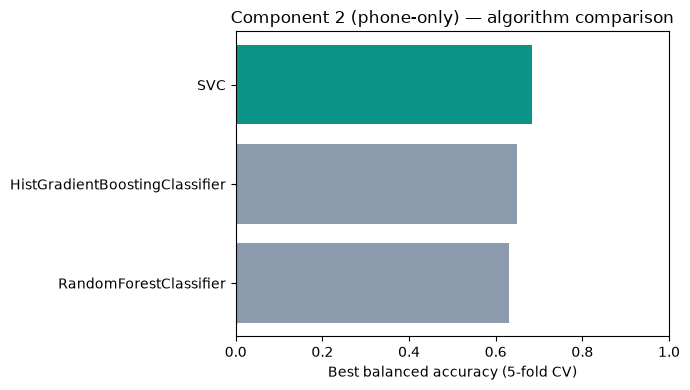

In [3]:
cv_results = pd.read_csv(CV_RESULTS_PATH)

summary = cv_results.groupby("algorithm")["mean_test_score"].agg(
    combinations_tried="count", best_score="max", average_score="mean"
).round(4).sort_values("best_score", ascending=False)
display(summary)

plt.figure(figsize=(7, 4))
plt.barh(summary.index, summary["best_score"], color=["#0C9388", "#8C9AAE", "#8C9AAE"])
plt.xlabel("Best balanced accuracy (5-fold CV)")
plt.xlim(0, 1)
plt.title("Component 2 (phone-only) — algorithm comparison")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [4]:
# Top 10 of the 30 combinations tried, ranked best first
cv_results[["algorithm", "param_select__k", "mean_test_score", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").head(10)

,algorithm,param_select__k,mean_test_score,std_test_score,rank_test_score
0,SVC,7,0.683929,0.090984,1
1,SVC,10,0.671429,0.024872,2
2,SVC,10,0.671429,0.024872,2
3,HistGradientBoostingClassifier,10,0.650000,0.043154,4
4,RandomForestClassifier,10,0.630357,0.069985,5
5,HistGradientBoostingClassifier,5,0.625000,0.057031,6
6,SVC,5,0.621429,0.087954,7
7,RandomForestClassifier,10,0.617857,0.041265,8
8,RandomForestClassifier,10,0.617857,0.041265,8
9,RandomForestClassifier,10,0.617857,0.041265,8


## Full classification report + confusion matrix



,precision,recall,f1-score,support
HC,0.776119,0.742857,0.759124,70.0
PD,0.581395,0.625000,0.602410,40.0
accuracy,0.700000,0.700000,0.700000,0.7
macro avg,0.678757,0.683929,0.680767,110.0
weighted avg,0.705311,0.700000,0.702137,110.0


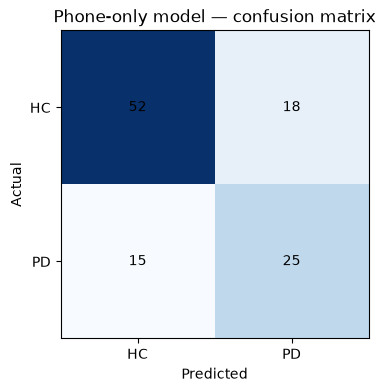

In [5]:
report_df = pd.DataFrame(metrics["classification_report"]).T
display(report_df)

cm = metrics["confusion_matrix"]
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "PD"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["HC", "PD"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Phone-only model — confusion matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i][j], ha="center", va="center")
plt.show()

## Avoid data leakage 

Every fold is split by `StratifiedGroupKFold` on `participant_id` — one person's recordings are never split across train and test in the same fold

In [6]:
import inspect
from component2_phonation import train_phone_only
source_lines = inspect.getsource(train_phone_only.main).splitlines()
for line in source_lines:
    if "StratifiedGroupKFold" in line or "groups=groups" in line:
        print(line.strip())

cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
search.fit(X, y, groups=groups)
y_pred_cv = cross_val_predict(best_model, X, y, groups=groups, cv=cv)
